## IQR Method

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Generate right-skewed income-like data with outliers
np.random.seed(42)

# 400 normal incomes from lognormal distribution (naturally skewed)
normal_income = np.random.lognormal(mean=10.0, sigma=0.4, size=400)

# Inject 6 outliers: 3 very low errors + 3 very high rich cases
injected = np.array([8000, 10000, 12000, 150000, 180000, 220000])
all_income = np.concatenate([normal_income, injected])

# Build DataFrame
df = pd.DataFrame({"income": all_income})
print(df.describe())

              income
count     406.000000
mean    25045.656851
std     17191.832212
min      6023.917439
25%     16827.137561
50%     22554.454572
75%     28501.195280
max    220000.000000


In [3]:
# Compute quartiles, IQR bounds and flag outliers
k = 1.5  # Use 1.5 for normal outliers, 3.0 for extreme only

# Calculate Q1, Q3 and IQR
Q1 = df["income"].quantile(0.25)
Q3 = df["income"].quantile(0.75)
IQR = Q3 - Q1

# Build lower and upper fences
lower_bound = Q1 - k * IQR
upper_bound = Q3 + k * IQR

# Flag outliers outside the fences
df["is_outlier"] = (df["income"] < lower_bound) | (df["income"] > upper_bound)

print(f"Q1: {Q1:.2f}, Q3: {Q3:.2f}, IQR: {IQR:.2f}")
print(f"Bounds: [{lower_bound:.2f}, {upper_bound:.2f}]")
print(f"Detected outliers: {df['is_outlier'].sum()}")
print(df[df["is_outlier"]].sort_values("income"))

Q1: 16827.14, Q3: 28501.20, IQR: 11674.06
Bounds: [-683.95, 46012.28]
Detected outliers: 19
            income  is_outlier
31    46208.141006        True
156   46458.271633        True
387   46651.872075        True
106   46839.135471        True
167   47038.288269        True
323   50866.249618        True
252   51475.563495        True
284   51700.014960        True
234   51926.141687        True
374   52118.381791        True
378   52887.440674        True
125   52901.250173        True
220   55595.827178        True
113   59000.243205        True
179   65386.275889        True
209  102856.757588        True
403  150000.000000        True
404  180000.000000        True
405  220000.000000        True


C:\Users\Lighthouse\AppData\Local\Temp\ipykernel_10912\797293779.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot(df["income"], vert=True, patch_artist=True)


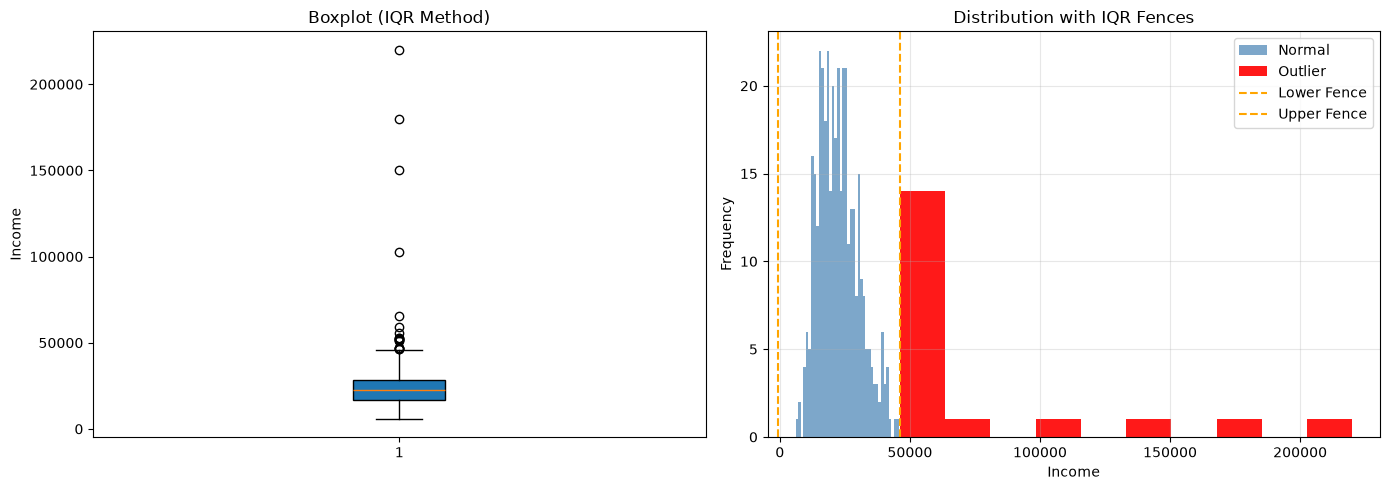

In [4]:
# Visualize with boxplot and histogram
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: boxplot shows quartiles and outliers automatically
axes[0].boxplot(df["income"], vert=True, patch_artist=True)
axes[0].set_title("Boxplot (IQR Method)")
axes[0].set_ylabel("Income")

# Right plot: histogram with bounds and outliers
axes[1].hist(df[~df["is_outlier"]]["income"], bins=40, color="steelblue", alpha=0.7, label="Normal")
axes[1].hist(df[df["is_outlier"]]["income"], bins=10, color="red", alpha=0.9, label="Outlier")
axes[1].axvline(lower_bound, color="orange", linestyle="--", label="Lower Fence")
axes[1].axvline(upper_bound, color="orange", linestyle="--", label="Upper Fence")
axes[1].set_title("Distribution with IQR Fences")
axes[1].set_xlabel("Income")
axes[1].set_ylabel("Frequency")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
# Experiment - compare IQR vs Z-Score on skewed data
# Z-Score with k=3 on the same skewed column
mean_val = df["income"].mean()
std_val = df["income"].std()
z_outliers = (((df["income"] - mean_val).abs() / std_val) > 3).sum()

iqr_outliers = df["is_outlier"].sum()

print(f"Z-Score detected: {z_outliers}")
print(f"IQR detected: {iqr_outliers}")
# Question: Which one found the injected low values? Why did the other miss them?

Z-Score detected: 4
IQR detected: 19
